In [1]:
# %pip install pandas
# %pip install matplotlib
# %pip install openpyxl
# %pip install xlrd
# %pip install numpy
# %pip install seaborn
# %pip install scikit-learn

In [2]:
import pandas as pd
import os
import glob
import warnings
from datetime import datetime
import re
import numpy as np
import matplotlib.pyplot as plt

# Loads

In [3]:
# Load the Excel file
file_path = '../data_set_2/atp_matches_till_2026.csv'
atp_matches = pd.read_csv(file_path)

# Load the Excel files
players_file = '../data_set_2/atp_players_till_2026.csv'
players = pd.read_csv(players_file)

# Example: Load the original ATP matches dataset (already used above)
data_set_3 = '../data_set_3/atp_tennis_matches.csv'
data_set_3_df = pd.read_csv(data_set_3)

/tmp/ipykernel_127297/3406090967.py:7: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  players = pd.read_csv(players_file)


In [4]:
# Combine first and last names to match match data
players['full_name'] = (players['name_first'].astype(str).str.strip() + ' ' + players['name_last'].astype(str).str.strip()).str.strip()

# Create a general player_info dictionary with both height and dob
player_info = dict(zip(
    players['full_name'],
    zip(players['height'], players['dob'])
))

# Drop the 'dob' and 'wikidata_id' columns
players = players.drop(columns=['wikidata_id','ioc'])

# Display the first few rows of the DataFrame
print(players.head())


   player_id name_first name_last hand         dob  height         full_name
0     100001    Gardnar    Mulloy    R  19131122.0   185.0    Gardnar Mulloy
1     100002     Pancho    Segura    R  19210620.0   168.0     Pancho Segura
2     100003      Frank   Sedgman    R  19271002.0   180.0     Frank Sedgman
3     100004   Giuseppe     Merlo    R  19271011.0     NaN    Giuseppe Merlo
4     100005    Richard  Gonzalez    R  19280509.0   188.0  Richard Gonzalez


In [5]:
cols_to_drop = [
    'winner_age', 'loser_age', 'winner_ht', 'loser_ht', 'match_key',
    'winner_name_clean', 'loser_name_clean', 'tourney_name_clean', 'tourney_date_str'
]

# Rename winner_name and loser_name to Player_1 and Player_2
atp_matches = atp_matches.rename(columns={'winner_name': 'Player_1', 'loser_name': 'Player_2'})

# Create match_winner column with the winner's name (now Player_1)
atp_matches['match_winner'] = atp_matches['Player_1']

atp_matches = atp_matches.drop(columns=cols_to_drop, errors='ignore')
print(atp_matches.columns)

# Remove tiebreak numbers in parentheses from the 'score' column
atp_matches['score'] = atp_matches['score'].astype(str).str.replace(r'\(\d+\)', '', regex=True).str.strip()

# ~3000 matches (mostly 1968-1980, plus 53 Davis Cup ones in 2023) have no surface: keep them as 'Unknown'
# (Elo then only updates the overall rating). Paris 2024 is the only Olympics coded 'O', the earlier ones are 'A'
atp_matches['surface'] = atp_matches['surface'].fillna('Unknown')
atp_matches['tourney_level'] = atp_matches['tourney_level'].replace({'O': 'A'})

print(atp_matches.tail())

Index(['tourney_name', 'surface', 'draw_size', 'tourney_level', 'tourney_date',
       'Player_1', 'Player_2', 'score', 'best_of', 'round', 'w_1stIn',
       'w_1stWon', 'w_SvGms', 'w_bpSaved', 'w_bpFaced', 'l_1stIn', 'l_1stWon',
       'l_SvGms', 'l_bpSaved', 'l_bpFaced', 'match_winner'],
      dtype='object')
                        tourney_name surface  draw_size tourney_level  \
199384  Davis Cup WG2 PO: RSA vs MNE    Hard        4.0             D   
199385  Davis Cup WG2 PO: RSA vs MNE    Hard        4.0             D   
199386  Davis Cup WG2 PO: THA vs PUR    Hard        4.0             D   
199387  Davis Cup WG2 PO: THA vs PUR    Hard        4.0             D   
199388  Davis Cup WG2 PO: THA vs PUR    Hard        4.0             D   

        tourney_date          Player_1           Player_2           score  \
199384      20260207    Philip Henning    Petar Jovanovic         6-3 6-2   
199385      20260207      Alec Beckley  Aleksa Krivokapic         7-6 6-3   
199386      20260

In [6]:
# Load data_set_3 (built by atp-tennis-daily-pull.ipynb, already in this schema)
data_set_3 = '../data_set_3/atp_tennis_matches.csv'
data_set_3_df = pd.read_csv(data_set_3)

# Define mapping from verbose round names to compact codes
round_mapping = {
    'Quarterfinals': 'QF',
    'Semifinals': 'SF',
    'The Final': 'F',
    'Final': 'F',
    'Round Robin': 'RR',
}

# Numbered rounds depend on the draw size: the last one before the QF is always R16, so with n numbered rounds
# round k is R(16 * 2^(n-k)) (32 draw: '1st Round' = R32, 128 draw: R128). Matches atp_matches' codes 99.9% of the time.
# Season = year of date + 10 days, because January tournaments sometimes start in late December.
round_num = data_set_3_df['round'].str.extract(r'^(\d)\w\w Round$')[0].astype(float)
season = (pd.to_datetime(data_set_3_df['tourney_date']) + pd.Timedelta(days=10)).dt.year
n_rounds = round_num.groupby([data_set_3_df['tourney_name'], season]).transform('max')
numbered = 'R' + (16 * 2 ** (n_rounds - round_num)).astype('Int64').astype(str)

# Rename columns for consistency
data_set_3_df = data_set_3_df.rename(columns={
    'winner_name': 'Player_1',
    'loser_name': 'Player_2',
    'winner_odds': 'Odd_1',
    'loser_odds': 'Odd_2'
})

# Apply mapping to the 'round' column
data_set_3_df['round'] = np.where(round_num.notna(), numbered, data_set_3_df['round'].map(round_mapping).fillna(data_set_3_df['round']))

# Convert 'tourney_date' to yyyymmdd format if it's not already
if data_set_3_df['tourney_date'].dtype == object:
    # Try to parse and convert to int yyyymmdd
    data_set_3_df['tourney_date'] = pd.to_datetime(data_set_3_df['tourney_date'], errors='coerce').dt.strftime('%Y%m%d')
    data_set_3_df['tourney_date'] = data_set_3_df['tourney_date'].astype('Int64')
elif np.issubdtype(data_set_3_df['tourney_date'].dtype, np.datetime64):
    # If already datetime, convert to yyyymmdd int
    data_set_3_df['tourney_date'] = data_set_3_df['tourney_date'].dt.strftime('%Y%m%d').astype('Int64')
else:
    # If it's int but in yyy-mm-dd or yyyy-mm-dd string format, fix those
    data_set_3_df['tourney_date'] = data_set_3_df['tourney_date'].astype(str).str.replace('-', '')
    data_set_3_df['tourney_date'] = pd.to_numeric(data_set_3_df['tourney_date'], errors='coerce').astype('Int64')

# Show the last few rows of the cleaned DataFrame
print(data_set_3_df.tail())


           tourney_name  tourney_date    court surface round  best_of  \
71545  Shanghai Masters      20261016  Outdoor    Hard    QF        3   
71546  Shanghai Masters      20261016  Outdoor    Hard    QF        3   
71547  Shanghai Masters      20261017  Outdoor    Hard    SF        3   
71548  Shanghai Masters      20261017  Outdoor    Hard    SF        3   
71549  Shanghai Masters      20261018  Outdoor    Hard     F        3   

          Player_1              Player_2          match_winner  Odd_1  Odd_2  \
71545      Ruud C.              Jodar R.              Jodar R.   2.10   1.73   
71546  Medvedev D.               Paul T.           Medvedev D.   1.40   3.00   
71547    Zverev A.  Davidovich Fokina A.  Davidovich Fokina A.   1.22   4.33   
71548     Jodar R.           Medvedev D.              Jodar R.   2.63   1.50   
71549     Jodar R.  Davidovich Fokina A.  Davidovich Fokina A.   1.73   2.10   

       PS_1  PS_2  Max_1  Max_2  BFE_1  BFE_2        score tourney_level  
71545

# Dataset Column Descriptions for Tennis Match Data

## Tournament Info
- **tourney_id**: Unique tournament identifier
- **tourney_name**: Name of the tournament (e.g., Wimbledon)
- **surface**: Court surface type (Hard, Clay, Grass, Carpet)
- **draw_size**: Number of players in the draw
- **tourney_level**: Tournament level (G = Grand Slam, M = Masters, A = ATP 500/250)
- **tourney_date**: Start date of the tournament (yyyymmdd)

## Match Info
- **match_num**: Unique identifier for the match within the tournament
- **round**: Round of the tournament (e.g., 1st Round, Quarterfinals, Final)
- **best_of**: Number of sets in the match (3 or 5)
- **score**: Final match score (e.g., "6-3 4-6 7-6(5)")
- **minutes**: Match duration in minutes

## Winner Info
- **winner_id**: Unique ID of the winning player
- **winner_seed**: Seed number of the winner
- **winner_entry**: Entry type (WC = Wild Card, Q = Qualifier, LL = Lucky Loser)
- **winner_name**: Full name of the winner
- **winner_hand**: Playing hand ('R' = right, 'L' = left)
- **winner_ht**: Height in cm
- **winner_ioc**: Country code (IOC standard)
- **winner_age**: Age at match time
- **winner_rank**: Pre-match ranking
- **winner_rank_points**: Pre-match ranking points

## Loser Info
- **loser_id**: Unique ID of the losing player
- **loser_seed**: Seed number of the loser
- **loser_entry**: Entry type
- **loser_name**: Full name of the loser
- **loser_hand**: Playing hand
- **loser_ht**: Height in cm
- **loser_ioc**: Country code
- **loser_age**: Age at match time
- **loser_rank**: Pre-match ranking
- **loser_rank_points**: Pre-match ranking points

## Serve Stats - Winner
- **w_ace**: Aces served by winner
- **w_df**: Double faults by winner
- **w_svpt**: Total serve points
- **w_1stIn**: First serves in
- **w_1stWon**: Points won on first serve
- **w_2ndWon**: Points won on second serve
- **w_SvGms**: Service games played
- **w_bpSaved**: Break points saved
- **w_bpFaced**: Break points faced

## Serve Stats - Loser
- **l_ace**: Aces served by loser
- **l_df**: Double faults by loser
- **l_svpt**: Total serve points
- **l_1stIn**: First serves in
- **l_1stWon**: Points won on first serve
- **l_2ndWon**: Points won on second serve
- **l_SvGms**: Service games played
- **l_bpSaved**: Break points saved
- **l_bpFaced**: Break points faced

In [7]:
print(f"Length of atp_matches: {len(atp_matches)}")
print(f"Number of matches after 2000 in atp_matches: {(atp_matches['tourney_date'] >= 20000101).sum()}")
print(f"Length of data_set_3_df: {len(data_set_3_df)}")

Length of atp_matches: 199389
Number of matches after 2000 in atp_matches: 79299
Length of data_set_3_df: 71550


In [8]:
import unicodedata

# The two datasets name players differently ("Novak Djokovic" vs "Djokovic N.") and date matches differently
# (tournament start vs match day), so a (tourney_name, tourney_date) key almost never matched and most 2000+
# matches were added twice, under two names per player. Instead: build the same player key for both datasets,
# pair identical matches, keep the data_set_3 copy (it has odds) and use one name per player.

def normalize_name(name):
    return str(name).lower().strip()

def norm_name(s):
    return re.sub(r'[^a-z]', '', unicodedata.normalize('NFKD', str(s)).encode('ascii', 'ignore').decode().lower())

def td_key(name):
    """'Del Potro J.M.' / 'Varillas J. P.' -> 'delpotro_j' / 'varillas_j' (surname + first initial)"""
    t = name.split()
    i = next((i for i, w in enumerate(t) if i and re.fullmatch(r'[A-Z][a-z]?\..*|[A-Z]{1,2}', w)), len(t))
    return norm_name(' '.join(t[:i])) + '_' + norm_name(t[i])[:1] if i < len(t) else norm_name(name)

def find_duplicates(sk, td):
    """Pairs each data_set_3 match with the atp_matches match with the same (winner, loser) keys whose tournament
    started between 15 days before and 1 day after it. Returns the mask of paired atp_matches rows, and the pairs."""
    l = td[['wk', 'lk']].assign(t=td['d'] + pd.Timedelta(days=1), td_row=td.index).sort_values('t')
    r = sk[['wk', 'lk', 'd']].drop_duplicates().assign(t=sk['d']).sort_values('t')
    pairs = pd.merge_asof(l, r, on='t', by=['wk', 'lk'], tolerance=pd.Timedelta(days=16)).dropna(subset=['d'])
    n_paired = pairs.groupby(['wk', 'lk', 'd']).size().rename('n')
    n_paired = sk[['wk', 'lk', 'd']].join(n_paired, on=['wk', 'lk', 'd'])['n'].fillna(0)
    # 1-to-1, so two players meeting twice in one event (round robin + final) are both counted
    return sk.groupby(['wk', 'lk', 'd']).cumcount() < n_paired, pairs

def compatible(a, b):
    """Same surname with another initial, same initial and one surname inside the other ('ramos_a' / 'ramosvinolas_a'),
    or first and last name swapped ('bu_y' / 'yunchaokete_b')."""
    (sa, ia), (sb, ib) = a.rpartition('_')[::2], b.rpartition('_')[::2]
    return (sa == sb != '' or (ia == ib and min(len(sa), len(sb)) >= 3 and (sa in sb or sb in sa))
            or (ia != '' != ib and sa.startswith(ib) and sb.startswith(ia)))

def learn_aliases(sk, td, dup, matched):
    """data_set_3 key -> atp_matches key for spelling variants and typos ('Ramos-Vinolas A.', 'Dolgopolov O.'),
    learned from still unpaired matches where the opponent and the dates agree, seen at least 3 times."""
    s, t = sk[~dup], td[~matched]
    cand = []
    for same, other in (('wk', 'lk'), ('lk', 'wk')):
        j = t[[same, other, 'd']].merge(s[[same, other, 'd']], on=same, suffixes=('_td', '_sk'))
        j = j[(j['d_td'] - j['d_sk']).dt.days.between(-1, 15) & (j[other + '_td'] != j[other + '_sk'])]
        cand.append(j[[other + '_td', other + '_sk']].set_axis(['td', 'sk'], axis=1))
    cand = pd.concat(cand)
    cand = cand[[compatible(a, b) for a, b in zip(cand['td'], cand['sk'])]].value_counts().reset_index(name='n')
    cand = cand[cand['n'] >= 3].drop_duplicates('td')  # value_counts is sorted, so this keeps the most frequent
    return dict(zip(cand['td'], cand['sk']))

sk, td = atp_matches.reset_index(drop=True), data_set_3_df
for df in (sk, td):
    df['tourney_date'] = pd.to_numeric(df['tourney_date'], errors='coerce').astype('Int64')
    df[['Player_1', 'Player_2', 'match_winner']] = df[['Player_1', 'Player_2', 'match_winner']].apply(lambda c: c.str.strip())
    df['d'] = pd.to_datetime(df['tourney_date'].astype(str), format='%Y%m%d')

# atp_matches itself sometimes spells one player two ways ('Edouard Roger Vasselin' / 'Edouard Roger-Vasselin'): keep the most common
spellings = pd.concat([sk['Player_1'], sk['Player_2']]).rename('name').value_counts().reset_index()  # most frequent first
spellings['canon'] = spellings.groupby(spellings['name'].map(norm_name))['name'].transform('first')
for c in ('Player_1', 'Player_2', 'match_winner'):
    sk[c] = sk[c].map(dict(zip(spellings['name'], spellings['canon'])))

# Player_1 is the winner from here on, as in atp_matches (the balanced dataset adds the mirrored row later)
swap = td['match_winner'] == td['Player_2']
pairs = [('Player_1', 'Player_2'), ('Odd_1', 'Odd_2'), ('PS_1', 'PS_2'), ('Max_1', 'Max_2'), ('BFE_1', 'BFE_2')]
td.loc[swap, [x for pair in pairs for x in pair]] = td.loc[swap, [x for pair in pairs for x in pair[::-1]]].values
td.loc[swap, 'score'] = td.loc[swap, 'score'].str.replace(r'(\d+)-(\d+)', r'\2-\1', regex=True)

sk_key = dict(zip(players['full_name'], players['name_last'].map(norm_name) + '_' + players['name_first'].fillna('').map(norm_name).str[:1]))
for c, k in (('Player_1', 'wk'), ('Player_2', 'lk')):
    sk[k] = sk[c].map(lambda n: sk_key.get(n) or norm_name(n.split()[-1]) + '_' + norm_name(n)[:1])
    td[k] = td[c].map(td_key)

dup, pairs = find_duplicates(sk, td)
matched = td.index.isin(pairs['td_row'])
aliases = learn_aliases(sk, td, dup, matched)
for k in ('wk', 'lk'):
    td.loc[~matched, k] = td.loc[~matched, k].replace(aliases)
dup, pairs = find_duplicates(sk, td)

# One name per player: atp_matches' full names (one per player id, back to 1968), chosen by majority over paired matches.
# Tournament names go the other way, to data_set_3's names.
STATS = [f'{s}_{c}' for s in ('w', 'l') for c in ('1stIn', '1stWon', 'SvGms', 'bpSaved', 'bpFaced')]
p = pairs.merge(sk[['wk', 'lk', 'd', 'Player_1', 'Player_2', 'tourney_name'] + STATS].drop_duplicates(['wk', 'lk', 'd']), on=['wk', 'lk', 'd'])
p = p.join(td[['Player_1', 'Player_2', 'tourney_name']], on='td_row', rsuffix='_td')
# Per year, from the nearest year with paired matches, because data_set_3 reuses a name for different players over time
# ('Ruud C.' = Christian Ruud until 2001, Casper Ruud from 2016; 'Martin A.' = Alberto, Andrej, then Andres Martin)
names = pd.concat([p[['Player_1_td', 'Player_1']].set_axis(['td', 'sk'], axis=1), p[['Player_2_td', 'Player_2']].set_axis(['td', 'sk'], axis=1)])
names['year'] = np.r_[p['d'].dt.year, p['d'].dt.year]
by_year = names.value_counts().reset_index().drop_duplicates(['td', 'year']).sort_values('year')
name_map = {}
# Spellings first seen after the atp_matches snapshot ends (May 2026, e.g. 'Tirante T. A.') can't be paired: use the
# player with the same key if exactly one was active since 2024. Players new after May 2026 keep data_set_3's name.
recent = sk[sk['tourney_date'] >= 20240101]
recent = pd.concat([recent[['wk', 'Player_1']].set_axis(['k', 'n'], axis=1), recent[['lk', 'Player_2']].set_axis(['k', 'n'], axis=1)]).drop_duplicates()
key_name = dict(recent.drop_duplicates('k', keep=False).values)
for n in (set(td['Player_1']) | set(td['Player_2'])) - set(by_year['td']):
    if td_key(n) in key_name:
        name_map[n] = key_name[td_key(n)]
tourneys = p[['tourney_name', 'tourney_name_td']].value_counts().reset_index().drop_duplicates('tourney_name')
for c in ('Player_1', 'Player_2', 'match_winner'):
    q = pd.DataFrame({'td': td[c].values, 'year': td['d'].dt.year.values, 'row': td.index}).sort_values('year')
    nearest = pd.merge_asof(q, by_year[['td', 'year', 'sk']], on='year', by='td', direction='nearest').set_index('row')['sk']
    td[c] = nearest.reindex(td.index).fillna(td[c].map(name_map)).fillna(td[c])
sk['tourney_name'] = sk['tourney_name'].map(dict(zip(tourneys['tourney_name'], tourneys['tourney_name_td']))).fillna(sk['tourney_name'])

# Serve/return stats only exist in atp_matches: copy them onto the paired data_set_3 rows (both have the winner first)
td = td.join(p.set_index('td_row')[STATS])

merged_data = pd.concat([td, sk[~dup]], ignore_index=True).drop(columns=['wk', 'lk', 'd'])
merged_data['tourney_name'] = merged_data['tourney_name'].apply(normalize_name)

# atp_matches gives every match of a tournament the same date and lists the final first, so order rounds within a
# date too (the loops below use stable sorts to keep this order, otherwise a final can be processed before its QF)
round_order = {'ER': 0, 'R128': 1, 'R64': 2, 'R32': 3, 'R16': 4, 'RR': 4, 'QF': 5, 'SF': 6, 'BR': 7, 'F': 8}
merged_data['round_order'] = merged_data['round'].map(round_order)
merged_data = merged_data.sort_values(['tourney_date', 'round_order'], kind='stable').drop(columns='round_order').reset_index(drop=True)

print(f"Learned {len(aliases)} name variants; {dup.sum()} atp_matches rows were already in data_set_3, added {(~dup).sum()}.")
print(f"Merged data shape: {merged_data.shape}")
print(merged_data[['tourney_name', 'tourney_date']].head())

# Sanity checks: winner first, one row and one name per match/player
assert (merged_data['Player_1'] == merged_data['match_winner']).all()
w2010 = merged_data[(merged_data['tourney_name'] == 'wimbledon') & (merged_data['tourney_date'] // 10000 == 2010) & (merged_data['round'] == 'F')]
assert w2010['Player_1'].tolist() == ['Rafael Nadal'], w2010
assert not merged_data[['Player_1', 'Player_2']].isin(['Djokovic N.', 'Novak Djokovic ']).any().any()


Learned 26 name variants; 70256 atp_matches rows were already in data_set_3, added 129133.
Merged data shape: (200683, 30)
  tourney_name  tourney_date
0       bombay      19671228
1       bombay      19671228
2       bombay      19671228
3       bombay      19671228
4     calcutta      19671228


In [9]:
# Players new on tour since June 2026 have no Sackmann name and keep tennis-data's short one ('Simakin I.'), which would cut
# their tour matches off from their Challenger history ('Ilia Simakin') in the ratings. They get the full name of the only
# player active since 2024 in the lower levels or in the current ranking whose surname and first initial fit.
from ratings import load_lower

def plain(s):
    return ' '.join(re.sub(r'[^a-z]+', ' ', unicodedata.normalize('NFKD', str(s)).encode('ascii', 'ignore').decode().lower()).split())

lower = load_lower('../data_set_2')
active = lower[lower['tourney_date'] >= 20240101]
candidates = {plain(n): n for n in set(active['winner_name']) | set(active['loser_name']) | set(pd.read_csv('../data_set_2/atp_current_ranking.csv')['name'])}
full_name = {}
for p in set(merged_data['Player_1']) | set(merged_data['Player_2']):
    m = re.match(r'^(.+)\s+([\w.-]+)\.$', p)
    if m:
        surname, initials = plain(m[1]), plain(m[2]).replace(' ', '')
        fits = [n for k, n in candidates.items() if k.endswith(' ' + surname) and k[:-len(surname)].replace(' ', '').startswith(initials)]
        if len(fits) == 1:
            full_name[p] = fits[0]
for col in ('Player_1', 'Player_2', 'match_winner'):
    merged_data[col] = merged_data[col].replace(full_name)
print(f"{len(full_name)} short names given their full name, e.g. {list(full_name.items())[:4]}")

29 short names given their full name, e.g. [('Mayo A.', 'Aidan Mayo'), ('Dahlin M.', 'Max Dahlin'), ('Silva D.', 'Daniel Dutra Da Silva'), ('Torres T.', 'Tiago Torres')]


In [10]:
merged_data.to_csv('../training_data_set/merged_data.csv', index=False)

In [11]:
# ...existing code...

def evaluate_winner_performance(score):
    """
    Improved evaluation of how dominant the winner's match was.

    Parameters:
    - score: str, e.g., "6-3 4-6 7-6(5)"

    Returns:
    - performance_score: float
    """
    if pd.isna(score):
        return 0  # Skip if the score is NaN
    sets = score.split()
    winner_sets = 0
    loser_sets = 0
    total_game_diff = 0
    tiebreaks = 0

    for set_score in sets:
        match = re.match(r"(\d+)-(\d+)(?:\((\d+)\))?", set_score)
        if not match:
            continue  # skip malformed sets

        p1_games = int(match.group(1))
        p2_games = int(match.group(2))
        tiebreak = match.group(3)

        if p1_games > p2_games:
            winner_sets += 1
            game_diff = p1_games - p2_games
        else:
            loser_sets += 1
            game_diff = p2_games - p1_games  # still use the diff, but flipped

        total_game_diff += game_diff

        if tiebreak is not None:
            tiebreaks += 1

    straight_sets_bonus = 1 if loser_sets == 0 else 0
    performance_score = (
        winner_sets * 2                             # reward set wins
        + total_game_diff / 2.0                     # reward game domination
        + straight_sets_bonus * 1.5                 # extra reward for clean win
        - tiebreaks * 0.5                           # penalize tight sets
        - loser_sets                                # penalize dropped sets
    )
    return round(performance_score, 2)

def evaluate_loser_performance(score):
    """
    Mirror of evaluate_winner_performance, but from the loser's perspective.
    """
    if pd.isna(score):
        return 0
    sets = score.split()
    loser_sets = 0
    winner_sets = 0
    total_game_diff = 0
    tiebreaks = 0

    for set_score in sets:
        match = re.match(r"(\d+)-(\d+)(?:\((\d+)\))?", set_score)
        if not match:
            continue

        p1_games = int(match.group(1))
        p2_games = int(match.group(2))
        tiebreak = match.group(3)

        if p2_games > p1_games:
            loser_sets += 1
            game_diff = p2_games - p1_games
        else:
            winner_sets += 1
            game_diff = p1_games - p2_games

        total_game_diff += game_diff

        if tiebreak is not None:
            tiebreaks += 1

    straight_sets_bonus = 1 if winner_sets == 0 else 0
    performance_score = (
        loser_sets * 2
        + total_game_diff / 2.0
        + straight_sets_bonus * 1.5
        - tiebreaks * 0.5
        - winner_sets
    )
    return round(performance_score, 2)

merged_data['Player_1_performance'] = merged_data['score'].apply(evaluate_winner_performance)
merged_data['Player_2_performance'] = merged_data['score'].apply(evaluate_loser_performance)

# Display the first few rows with the new columns
print(merged_data.tail())

            tourney_name  tourney_date    court surface round  best_of  \
200678  shanghai masters      20261016  Outdoor    Hard    QF        3   
200679  shanghai masters      20261016  Outdoor    Hard    QF        3   
200680  shanghai masters      20261017  Outdoor    Hard    SF        3   
200681  shanghai masters      20261017  Outdoor    Hard    SF        3   
200682  shanghai masters      20261018  Outdoor    Hard     F        3   

                           Player_1          Player_2  \
200678                 Rafael Jodar       Casper Ruud   
200679              Daniil Medvedev        Tommy Paul   
200680  Alejandro Davidovich Fokina  Alexander Zverev   
200681                 Rafael Jodar   Daniil Medvedev   
200682  Alejandro Davidovich Fokina      Rafael Jodar   

                       match_winner  Odd_1  ...  w_bpSaved  w_bpFaced  \
200678                 Rafael Jodar   1.73  ...        NaN        NaN   
200679              Daniil Medvedev   1.40  ...        NaN        

# Performance Score Formula Explanation with Examples

The `performance_score` formula evaluates how dominant a tennis player's victory was. Let me explain each component using concrete examples:





## Example 1: Dominant straight-sets win
**Score: 6-1 6-2**
- winner_sets = 2 (won both sets)
- total_game_diff = (6-1) + (6-2) = 9 games
- straight_sets_bonus = 1 (won in straight sets)
- tiebreaks = 0 (no tiebreaks)
- loser_sets = 0 (opponent didn't win any sets)

**Performance score = (2×2) + (9÷2) + (1×1.5) - (0×0.5) - 0 = 4 + 4.5 + 1.5 = 10.0**

High score reflects complete dominance - straight sets with lopsided game counts.

## Example 2: Close straight-sets win with tiebreak
**Score: 7-6(5) 7-5**
- winner_sets = 2
- total_game_diff = (7-6) + (7-5) = 3 games
- straight_sets_bonus = 1
- tiebreaks = 1 (first set tiebreak)
- loser_sets = 0

**Performance score = (2×2) + (3÷2) + (1×1.5) - (1×0.5) - 0 = 4 + 1.5 + 1.5 - 0.5 = 6.5**

Lower score than Example 1 despite straight sets win, because games were closer and required a tiebreak.

## Example 3: Three-set comeback victory
**Score: 4-6 6-3 6-2**
- winner_sets = 2
- total_game_diff = (-2) + 3 + 4 = 5 games
- straight_sets_bonus = 0 (lost a set)
- tiebreaks = 0
- loser_sets = 1

**Performance score = (2×2) + (5÷2) + (0×1.5) - (0×0.5) - 1 = 4 + 2.5 - 1 = 5.5**

Lower than both previous examples because the player dropped a set.

## Example 4: Five-set battle with tiebreaks
**Score: 7-6(4) 4-6 6-7(2) 6-4 7-5**
- winner_sets = 3
- total_game_diff = 1 + (-2) + (-1) + 2 + 2 = 2 games
- straight_sets_bonus = 0
- tiebreaks = 2
- loser_sets = 2

**Performance score = (3×2) + (2÷2) + (0×1.5) - (2×0.5) - 2 = 6 + 1 - 1 - 2 = 4.0**

Despite winning a five-setter, this scores lowest because it was highly competitive with multiple lost sets and tiebreaks.

In [12]:
# Elo per surface and overall (FiveThirtyEight-style K, margin of victory) and Glicko-2, computed in ratings.py, which
# predict_matches.py shares. Besides tour matches the ratings learn from Challengers, tour qualifying and Futures, so
# newcomers arrive on tour with a rating: on 2012-2026 test matches log loss 0.5968 -> 0.5849.
from ratings import rate, SURFACES

ordered = merged_data.sort_values('tourney_date', kind='stable')
rated, player_ratings = rate(ordered, lower)
for col in rated.columns:
    merged_data.loc[ordered.index, col] = rated[col].values
player_ratings.to_csv('../training_data_set/player_ratings.csv')  # everyone's latest ratings, read by predict_matches.py
print(f"Rated {len(ordered)} tour and {len(lower)} lower-level matches ({len(player_ratings)} players)")

# Calculate Elo differences before the match
merged_data['elo_diff_pre'] = merged_data['winner_overall_elo_pre'] - merged_data['loser_overall_elo_pre']
merged_data['surface_elo_diff_pre'] = 0.0
for s in SURFACES:
    k = merged_data['surface'] == s
    merged_data.loc[k, 'surface_elo_diff_pre'] = merged_data.loc[k, f'winner_{s.lower()}_elo_pre'] - merged_data.loc[k, f'loser_{s.lower()}_elo_pre']

# Display a sample of the data with Elo ratings
cols_to_show = ['Player_1', 'Player_2', 'surface',
                'winner_overall_elo_pre', 'loser_overall_elo_pre',
                'winner_overall_elo_post', 'loser_overall_elo_post',
                'elo_diff_pre', 'surface_elo_diff_pre']
print("Sample of matches with Elo ratings:")
print(merged_data[cols_to_show].head(10))


Rated 200683 tour and 768814 lower-level matches (29699 players)
Sample of matches with Elo ratings:
          Player_1           Player_2  surface  winner_overall_elo_pre  \
0   Alex Metreveli          Jan Kodes     Clay             1400.000000   
1  Jaidip Mukerjea          Jan Kukal     Clay             1400.000000   
2     Premjit Lall       Ilie Nastase     Clay             1400.000000   
3       Ion Tiriac      Shyam Minotra     Clay             1400.000000   
4       Ion Tiriac  Zeljko Franulovic  Unknown             1468.289723   
5     Premjit Lall       Vinay Dhawan  Unknown             1455.448920   
6  Jaidip Mukerjea       Gaurav Misra  Unknown             1456.470348   
7     Ilie Nastase      Shyam Minotra  Unknown             1344.551080   
8   Alex Metreveli    Jaidip Mukerjea     Clay             1464.652992   
9       Ion Tiriac       Premjit Lall     Clay             1516.082534   

   loser_overall_elo_pre  winner_overall_elo_post  loser_overall_elo_post  \
0      

Highest rated player: Jannik Sinner with rating: 2818.6


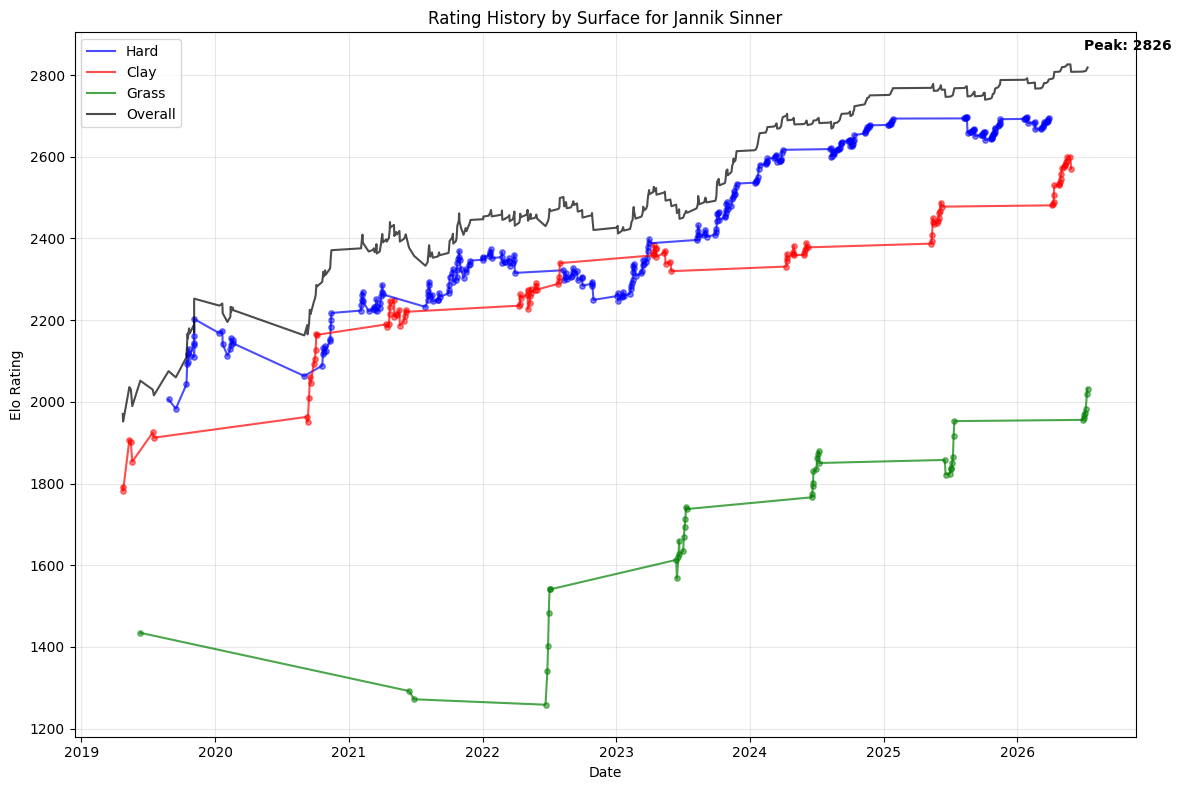

In [13]:
# Find the player with the highest overall rating (at the END of the Elo calculation)
highest_rated_player = player_ratings['elo_overall'].idxmax()
highest_rating = player_ratings['elo_overall'].max()
print(f"Highest rated player: {highest_rated_player} with rating: {highest_rating:.1f}")

# Create a dictionary to store player rating history by surface
player_rating_history = {surface: {} for surface in ['Hard', 'Clay', 'Grass', 'Carpet', 'Overall']}

# Extract rating history from merged_data for the highest rated player
filtered_data = merged_data[
    (merged_data['Player_1'] == highest_rated_player) | 
    (merged_data['Player_2'] == highest_rated_player)
].sort_values('tourney_date')

# Initialize empty history lists for each surface
for surface in player_rating_history.keys():
    player_rating_history[surface][highest_rated_player] = []

# Populate history for each match (track both surface and overall Elo after each match)
for _, match in filtered_data.iterrows():
    date = match['tourney_date']
    # Use the actual surface for surface Elo, fallback to 'Overall' if not recognized
    surface = match['surface'] if pd.notna(match['surface']) and match['surface'] in ['Hard', 'Clay', 'Grass', 'Carpet'] else 'Overall'
    match_date = pd.to_datetime(str(date), format='%Y%m%d')

    # Get the post-match Elo for the player, depending on win/loss
    if match['match_winner'] == highest_rated_player:
        surface_rating = match.get(f'winner_{surface.lower()}_elo_post', np.nan)
        overall_rating = match.get('winner_overall_elo_post', np.nan)
    else:
        surface_rating = match.get(f'loser_{surface.lower()}_elo_post', np.nan)
        overall_rating = match.get('loser_overall_elo_post', np.nan)

    # Record the rating history for this surface (only if not nan)
    if pd.notna(surface_rating):
        player_rating_history[surface][highest_rated_player].append((match_date, surface_rating))
    # Always record the overall rating (only if not nan)
    if pd.notna(overall_rating):
        player_rating_history['Overall'][highest_rated_player].append((match_date, overall_rating))

# Plot the rating history
plt.figure(figsize=(12, 8))

# Define colors for different surfaces
surface_colors = {
    'Hard': 'blue',
    'Clay': 'red',
    'Grass': 'green',
    'Carpet': 'purple',
    'Overall': 'black'
}

# Plot each surface's rating history
for surface, color in surface_colors.items():
    history = player_rating_history[surface][highest_rated_player]
    if history:  # Only plot if history exists
        dates, ratings = zip(*history)
        plt.plot(dates, ratings, label=f"{surface}", color=color, alpha=0.7)
        # Add markers for more readability (skip for 'Overall' to avoid clutter)
        if surface != 'Overall':
            plt.scatter(dates, ratings, color=color, s=15, alpha=0.5)

# Configure the plot
plt.xlabel('Date')
plt.ylabel('Elo Rating')
plt.title(f'Rating History by Surface for {highest_rated_player}')
plt.legend()
plt.grid(True, alpha=0.3)

# Format x-axis to show years
from matplotlib.dates import YearLocator, DateFormatter
plt.gca().xaxis.set_major_locator(YearLocator())
plt.gca().xaxis.set_major_formatter(DateFormatter('%Y'))

# Add annotation for peak overall Elo
overall_history = player_rating_history['Overall'][highest_rated_player]
if overall_history:
    peak_date, peak_rating = max(overall_history, key=lambda x: x[1])
    plt.annotate(f'Peak: {peak_rating:.0f}', 
                 xy=(peak_date, peak_rating),
                 xytext=(10, 10),
                 textcoords='offset points',
                 color='black',
                 fontweight='bold')

plt.tight_layout()
plt.show()

In [14]:
# Elo momentum: how much a player's overall Elo changed over their last 5 matches, BEFORE this match
# (same window as recent form / consecutive wins; > 0 = rising, < 0 = slumping)
MOMENTUM_WINDOW = 5

order = merged_data.sort_values('tourney_date', kind='stable').index
changes = pd.concat([
    pd.DataFrame({
        'side': side,
        'pos': np.arange(len(order)),
        'player': merged_data.loc[order, f'Player_{side}'],
        'change': merged_data.loc[order, f'{who}_overall_elo_post'] - merged_data.loc[order, f'{who}_overall_elo_pre'],
    })
    for side, who in ((1, 'winner'), (2, 'loser'))  # Player_1 is the winner (see merge)
]).sort_values('pos', kind='stable')

# shift(1): only the player's previous matches count, never this one
changes['momentum'] = changes.groupby('player')['change'].transform(lambda c: c.shift(1).rolling(MOMENTUM_WINDOW, min_periods=1).sum())
for side in (1, 2):
    merged_data[f'Player_{side}_elo_momentum'] = changes.loc[changes['side'] == side, 'momentum']

print(merged_data[['Player_1', 'Player_2', 'Player_1_elo_momentum', 'Player_2_elo_momentum']].tail(10))


                           Player_1               Player_2  \
200673                  Casper Ruud  Felix Auger Aliassime   
200674              Daniil Medvedev     Stefanos Tsitsipas   
200675                   Tommy Paul            Zizou Bergs   
200676  Alejandro Davidovich Fokina             Arthur Gea   
200677             Alexander Zverev         Alex De Minaur   
200678                 Rafael Jodar            Casper Ruud   
200679              Daniil Medvedev             Tommy Paul   
200680  Alejandro Davidovich Fokina       Alexander Zverev   
200681                 Rafael Jodar        Daniil Medvedev   
200682  Alejandro Davidovich Fokina           Rafael Jodar   

        Player_1_elo_momentum  Player_2_elo_momentum  
200673             -24.085926             -19.523711  
200674              20.361574              16.256040  
200675              -3.939508              27.438604  
200676              25.048751              61.049234  
200677               1.578963             

In [15]:
# Serve/return form: 1st serve points won %, break points converted % and return games won % over the player's
# last 10 matches, BEFORE this match (matches without stats don't count; stats exist from 1991 to May 2026)
STATS_WINDOW = 10

order = merged_data.sort_values('tourney_date', kind='stable').index
m = merged_data.loc[order]
per_match = pd.concat([
    pd.DataFrame({
        'side': side,
        'row': order,
        'player': m[f'Player_{side}'].values,
        'first_won': m[f'{me}_1stWon'].values,
        'first_in': m[f'{me}_1stIn'].values,
        'breaks': (m[f'{opp}_bpFaced'] - m[f'{opp}_bpSaved']).values,
        'bp_chances': m[f'{opp}_bpFaced'].values,
        'return_games': m[f'{opp}_SvGms'].values,
        'pos': np.arange(len(order)),
    })
    for side, me, opp in ((1, 'w', 'l'), (2, 'l', 'w'))  # Player_1 is the winner (see merge)
]).sort_values('pos', kind='stable').reset_index(drop=True)

# shift(1): only the player's previous matches count, never this one; ratios of sums, so long matches weigh more
cols = ['first_won', 'first_in', 'breaks', 'bp_chances', 'return_games']
past = (per_match.groupby('player')[cols].shift(1)
        .groupby(per_match['player']).rolling(STATS_WINDOW, min_periods=1).sum()
        .reset_index(level=0, drop=True))
per_match['first_serve_won'] = past['first_won'] / past['first_in']
per_match['bp_converted'] = past['breaks'] / past['bp_chances']
per_match['return_games_won'] = past['breaks'] / past['return_games']

for side in (1, 2):
    s = per_match[per_match['side'] == side].set_index('row').replace([np.inf, -np.inf], np.nan)
    for f in ('first_serve_won', 'bp_converted', 'return_games_won'):
        merged_data[f'Player_{side}_{f}'] = s[f]

print(merged_data[['Player_1', 'Player_2', 'Player_1_first_serve_won', 'Player_1_bp_converted', 'Player_1_return_games_won']].tail(10))


                           Player_1               Player_2  \
200673                  Casper Ruud  Felix Auger Aliassime   
200674              Daniil Medvedev     Stefanos Tsitsipas   
200675                   Tommy Paul            Zizou Bergs   
200676  Alejandro Davidovich Fokina             Arthur Gea   
200677             Alexander Zverev         Alex De Minaur   
200678                 Rafael Jodar            Casper Ruud   
200679              Daniil Medvedev             Tommy Paul   
200680  Alejandro Davidovich Fokina       Alexander Zverev   
200681                 Rafael Jodar        Daniil Medvedev   
200682  Alejandro Davidovich Fokina           Rafael Jodar   

        Player_1_first_serve_won  Player_1_bp_converted  \
200673                       NaN                    NaN   
200674                       NaN                    NaN   
200675                       NaN                    NaN   
200676                       NaN                    NaN   
200677                

In [16]:
# Playing hand from the Sackmann player list: 1 = left-handed, 0 = right-handed, NaN = unknown (~4% of matches)
hand = players.drop_duplicates('full_name').set_index('full_name')['hand'].map({'L': 1, 'R': 0})
for side in (1, 2):
    merged_data[f'Player_{side}_left'] = merged_data[f'Player_{side}'].map(hand)


In [17]:
# Handedness matchups: compared with a calibrated Elo expectation (P(win) = sigmoid(a * elo_diff)), does the lefty win
# more often in left vs right matches, and which players do better/worse against lefties than against righties?
from sklearn.linear_model import LogisticRegression

hm = merged_data[merged_data[['Player_1_left', 'Player_2_left']].notna().all(axis=1)]
d = hm['elo_diff_pre'].values  # Player_1 is the winner
calib = LogisticRegression().fit(np.r_[d, -d].reshape(-1, 1), np.r_[np.ones(len(d)), np.zeros(len(d))])
p_winner = calib.predict_proba(d.reshape(-1, 1))[:, 1]

mixed = (hm['Player_1_left'] != hm['Player_2_left']).values
lefty_won = (hm['Player_1_left'].values == 1)[mixed]
p_lefty = np.where(lefty_won, p_winner[mixed], 1 - p_winner[mixed])
lefty = pd.DataFrame({
    'surface': hm['surface'].values[mixed],
    'era': pd.cut(hm['tourney_date'].values[mixed], [0, 19910101, 20100101, 30000000], right=False,
                  labels=['before 1991', '1991-2009', '2010-2026']),
    'won': lefty_won, 'expected': p_lefty, 'var': p_lefty * (1 - p_lefty),
})
for by in ('surface', 'era'):
    g = lefty.groupby(by, observed=True).agg(n=('won', 'size'), won=('won', 'mean'), expected=('expected', 'mean'), var=('var', 'sum'))
    g['excess'] = g['won'] - g['expected']
    g['z'] = g['excess'] / (np.sqrt(g['var']) / g['n'])
    print(f"Lefty win rate vs Elo expectation in left vs right matches, by {by}:")
    print(g.drop(columns='var').round(3), '\n')

# Players who do much better/worse against lefties than against righties (since 1991, >= 40 matches each way)
rows = pd.concat([
    pd.DataFrame({'player': hm['Player_1'], 'opp_left': hm['Player_2_left'], 'won': 1, 'exp': p_winner, 'date': hm['tourney_date']}),
    pd.DataFrame({'player': hm['Player_2'], 'opp_left': hm['Player_1_left'], 'won': 0, 'exp': 1 - p_winner, 'date': hm['tourney_date']}),
])
rows = rows[rows['date'] >= 19910101].assign(excess=lambda r: r['won'] - r['exp'], var=lambda r: r['exp'] * (1 - r['exp']))
g = rows.groupby(['player', 'opp_left']).agg(n=('won', 'size'), excess=('excess', 'mean'), var=('var', 'sum')).unstack('opp_left').dropna()
g = g[(g[('n', 1.0)] >= 40) & (g[('n', 0.0)] >= 40)]
vs = pd.DataFrame({'matches_vs_lefties': g[('n', 1.0)], 'excess_vs_lefties': g[('excess', 1.0)], 'excess_vs_righties': g[('excess', 0.0)]})
vs['difference'] = vs['excess_vs_lefties'] - vs['excess_vs_righties']
vs['z'] = vs['difference'] / np.sqrt(g[('var', 1.0)] / g[('n', 1.0)] ** 2 + g[('var', 0.0)] / g[('n', 0.0)] ** 2)
print(f"{(vs['z'].abs() > 2).sum()} of {len(vs)} players differ with |z| > 2 (about {0.0455 * len(vs):.0f} expected by pure chance)")
print(vs.sort_values('z').round(3).iloc[np.r_[0:6, -6:0]])


Lefty win rate vs Elo expectation in left vs right matches, by surface:
             n    won  expected  excess      z
surface                                       
Carpet    5645  0.556     0.545   0.011  1.818
Clay     16316  0.531     0.525   0.006  1.688
Grass     5657  0.523     0.508   0.015  2.458
Hard     19030  0.497     0.500  -0.003 -0.962
Unknown    378  0.611     0.592   0.019  0.881 

Lefty win rate vs Elo expectation in left vs right matches, by era:
                 n    won  expected  excess      z
era                                               
before 1991  19738  0.563     0.552   0.011  3.533
1991-2009    16205  0.495     0.495  -0.000 -0.103
2010-2026    11083  0.479     0.481  -0.002 -0.459 

20 of 279 players differ with |z| > 2 (about 13 expected by pure chance)
                    matches_vs_lefties  excess_vs_lefties  excess_vs_righties  \
player                                                                          
Hernan Gumy                       44.

In [18]:
# Age on match day (from date of birth) and career tour-level matches played BEFORE this one.
# Elo lags behind careers: young players beat their Elo, older ones fall short, at any level of experience
dob = pd.to_datetime(players.drop_duplicates('full_name').set_index('full_name')['dob'].dropna().astype(int).astype(str),
                     format='%Y%m%d', errors='coerce')
match_day = pd.to_datetime(merged_data['tourney_date'].astype(str), format='%Y%m%d')

order = merged_data.sort_values('tourney_date', kind='stable').index
career = pd.concat([
    pd.DataFrame({'side': side, 'pos': np.arange(len(order)), 'row': order, 'player': merged_data.loc[order, f'Player_{side}'].values})
    for side in (1, 2)
]).sort_values('pos', kind='stable')
career['matches'] = career.groupby('player').cumcount()

for side in (1, 2):
    # ponytail: dob is looked up by name, so namesakes can get each other's birth date; ages outside 14-50 are dropped
    # as obviously wrong (~0.1%). Keep Sackmann's player ids through the merge if this ever matters more.
    age = (match_day - merged_data[f'Player_{side}'].map(dob)).dt.days / 365.25
    merged_data[f'Player_{side}_age'] = age.where(age.between(14, 50))
    merged_data[f'Player_{side}_career_matches'] = career[career['side'] == side].set_index('row')['matches']

print(merged_data[['Player_1', 'Player_1_age', 'Player_1_career_matches', 'Player_2', 'Player_2_age', 'Player_2_career_matches']].tail(5))


                           Player_1  Player_1_age  Player_1_career_matches  \
200678                 Rafael Jodar     20.079398                       58   
200679              Daniil Medvedev     30.677618                      666   
200680  Alejandro Davidovich Fokina     27.367556                      350   
200681                 Rafael Jodar     20.082136                       59   
200682  Alejandro Davidovich Fokina     27.370294                      351   

                Player_2  Player_2_age  Player_2_career_matches  
200678       Casper Ruud     27.816564                      498  
200679        Tommy Paul     29.415469                      404  
200680  Alexander Zverev     29.492129                      822  
200681   Daniil Medvedev     30.680356                      667  
200682      Rafael Jodar     20.084873                       60  


In [19]:
# Indoor/outdoor: known for data_set_3 matches (2000+); other matches take their tournament's usual setting when known
court = merged_data['court'].where(merged_data['court'].isin(['Indoor', 'Outdoor']))
usual = court.groupby(merged_data['tourney_name']).agg(lambda c: c.mode().iat[0] if c.notna().any() else np.nan)
merged_data['indoor'] = court.fillna(merged_data['tourney_name'].map(usual)).map({'Indoor': 1, 'Outdoor': 0})

# Per player, BEFORE this match: win rate under the same conditions (indoor or outdoor), and days since they last
# retired injured or gave a walkover (NaN = never). Retirements/walkovers: atp_matches until May 2026, data_set_3 after.
gave_up = merged_data['score'].astype(str).str.contains('RET|W/O|Walkover')
long = pd.concat([
    pd.DataFrame({'side': side, 'pos': np.arange(len(order)), 'row': order,
                  'player': merged_data.loc[order, f'Player_{side}'].values, 'date': match_day.loc[order].values,
                  'indoor': merged_data.loc[order, 'indoor'].values, 'won': int(side == 1),
                  'gave_up': (side == 2) & gave_up.loc[order].values})  # Player_1 is the winner
    for side in (1, 2)
]).sort_values('pos', kind='stable').reset_index(drop=True)

known = long['indoor'].notna()
same_conditions = long[known].groupby(['player', 'indoor'])
long.loc[known, 'conditions_win_rate'] = (same_conditions['won'].cumsum() - long.loc[known, 'won']) / same_conditions.cumcount()

last_gave_up = long['date'].where(long['gave_up']).groupby(long['player']).shift(1).groupby(long['player']).ffill()
long['days_since_retirement'] = (long['date'] - last_gave_up).dt.days

for side in (1, 2):
    s = long[long['side'] == side].set_index('row')
    merged_data[f'Player_{side}_conditions_win_rate'] = s['conditions_win_rate'].replace([np.inf, -np.inf], np.nan)
    merged_data[f'Player_{side}_days_since_retirement'] = s['days_since_retirement']

print(merged_data['indoor'].value_counts(dropna=False).to_dict())
print(merged_data[['Player_1', 'Player_2', 'indoor', 'Player_1_conditions_win_rate', 'Player_2_days_since_retirement']].tail(5))


{0.0: 111671, nan: 63843, 1.0: 25169}
                           Player_1          Player_2  indoor  \
200678                 Rafael Jodar       Casper Ruud     0.0   
200679              Daniil Medvedev        Tommy Paul     0.0   
200680  Alejandro Davidovich Fokina  Alexander Zverev     0.0   
200681                 Rafael Jodar   Daniil Medvedev     0.0   
200682  Alejandro Davidovich Fokina      Rafael Jodar     0.0   

        Player_1_conditions_win_rate  Player_2_days_since_retirement  
200678                      0.722222                            61.0  
200679                      0.712000                           596.0  
200680                      0.553957                          1597.0  
200681                      0.727273                           382.0  
200682                      0.555556                             NaN  


In [20]:
MIN_H2H_MATCHES = 3  # Only consider H2H as strong feature if at least this many meetings

# Initialize columns
merged_data['h2h_wins'] = 0
merged_data['h2h_losses'] = 0
merged_data['h2h_surface_wins'] = 0
merged_data['h2h_surface_losses'] = 0
merged_data['h2h_recent_wins'] = 0
merged_data['h2h_recent_losses'] = 0
merged_data['perf_win'] = np.nan
merged_data['perf_loss'] = np.nan

# Historical dictionaries
historical_h2h = {}  # (player1, player2): [wins, losses]
historical_h2h_surface = {}  # (player1, player2, surface): [wins, losses]
historical_perf = {}  # (player1, player2): [total_perf, match_count]
historical_h2h_dates = {}  # (player1, player2): [dates]

for idx, match in merged_data.sort_values('tourney_date', kind='stable').iterrows():
    player1 = match['Player_1']
    player2 = match['Player_2']
    winner = match['match_winner']
    surface = match['surface']
    date = match['tourney_date']

    # Assign roles for H2H tracking: always (player1, player2)
    h2h_key = (player1, player2)
    h2h_rev_key = (player2, player1)
    surf_key = (player1, player2, surface)
    surf_rev_key = (player2, player1, surface)

    # Initialize if not present
    if h2h_key not in historical_h2h:
        historical_h2h[h2h_key] = [0, 0]
    if h2h_rev_key not in historical_h2h:
        historical_h2h[h2h_rev_key] = [0, 0]
    if surf_key not in historical_h2h_surface:
        historical_h2h_surface[surf_key] = [0, 0]
    if surf_rev_key not in historical_h2h_surface:
        historical_h2h_surface[surf_rev_key] = [0, 0]
    if h2h_key not in historical_h2h_dates:
        historical_h2h_dates[h2h_key] = []
    if h2h_rev_key not in historical_h2h_dates:
        historical_h2h_dates[h2h_rev_key] = []
    if (player1, player2) not in historical_perf:
        historical_perf[(player1, player2)] = [0, 0]
    if (player2, player1) not in historical_perf:
        historical_perf[(player2, player1)] = [0, 0]

    # Assign features for player1 perspective (BEFORE adding this match, to avoid leakage)
    merged_data.at[idx, 'h2h_wins'] = historical_h2h[h2h_key][0]
    merged_data.at[idx, 'h2h_losses'] = historical_h2h[h2h_key][1]
    merged_data.at[idx, 'h2h_surface_wins'] = historical_h2h_surface[surf_key][0]
    merged_data.at[idx, 'h2h_surface_losses'] = historical_h2h_surface[surf_key][1]
    recent_meetings = [d for d in historical_h2h_dates[h2h_key] if d < date][-3:]
    recent_meetings_rev = [d for d in historical_h2h_dates[h2h_rev_key] if d < date][-3:]
    merged_data.at[idx, 'h2h_recent_wins'] = len(recent_meetings)
    merged_data.at[idx, 'h2h_recent_losses'] = len(recent_meetings_rev)
    if historical_perf[(player1, player2)][1] > 0:
        merged_data.at[idx, 'perf_win'] = historical_perf[(player1, player2)][0] / historical_perf[(player1, player2)][1]
    if historical_perf[(player2, player1)][1] > 0:
        merged_data.at[idx, 'perf_loss'] = historical_perf[(player2, player1)][0] / historical_perf[(player2, player1)][1]

    # Assign win/loss for player1 perspective
    if winner == player1:
        historical_h2h[h2h_key][0] += 1
        historical_h2h[h2h_rev_key][1] += 1
        historical_h2h_surface[surf_key][0] += 1
        historical_h2h_surface[surf_rev_key][1] += 1
        perf_score = match['Player_1_performance'] if 'Player_1_performance' in match else 0
        historical_perf[(player1, player2)][0] += perf_score
        historical_perf[(player1, player2)][1] += 1
    else:
        historical_h2h[h2h_key][1] += 1
        historical_h2h[h2h_rev_key][0] += 1
        historical_h2h_surface[surf_key][1] += 1
        historical_h2h_surface[surf_rev_key][0] += 1
        perf_score = match['Player_2_performance'] if 'Player_2_performance' in match else 0
        historical_perf[(player2, player1)][0] += perf_score
        historical_perf[(player2, player1)][1] += 1

    # Dates for recency
    historical_h2h_dates[h2h_key].append(date)

# Calculate win rates
merged_data['h2h_win_rate'] = (merged_data['h2h_wins'] + 1) / (merged_data['h2h_wins'] + merged_data['h2h_losses'] + 2)
merged_data['h2h_surface_win_rate'] = (merged_data['h2h_surface_wins'] + 1) / (merged_data['h2h_surface_wins'] + merged_data['h2h_surface_losses'] + 2)
merged_data['h2h_recent_win_rate'] = (merged_data['h2h_recent_wins'] + 1) / (merged_data['h2h_recent_wins'] + merged_data['h2h_recent_losses'] + 2)

# Filter for meaningful H2H sample
merged_data['has_meaningful_h2h'] = (merged_data['h2h_wins'] + merged_data['h2h_losses']) >= MIN_H2H_MATCHES

# Display a sample of the new H2H features
print(merged_data[['Player_1', 'Player_2', 'surface', 'h2h_wins', 'h2h_losses', 'h2h_win_rate',
                   'h2h_surface_wins', 'h2h_surface_losses', 'h2h_surface_win_rate',
                   'h2h_recent_wins', 'h2h_recent_losses', 'h2h_recent_win_rate',
                   'has_meaningful_h2h', 'perf_win', 'perf_loss']].tail(10))

                           Player_1               Player_2 surface  h2h_wins  \
200673                  Casper Ruud  Felix Auger Aliassime    Hard         3   
200674              Daniil Medvedev     Stefanos Tsitsipas    Hard        10   
200675                   Tommy Paul            Zizou Bergs    Hard         1   
200676  Alejandro Davidovich Fokina             Arthur Gea    Hard         0   
200677             Alexander Zverev         Alex De Minaur    Hard         8   
200678                 Rafael Jodar            Casper Ruud    Hard         0   
200679              Daniil Medvedev             Tommy Paul    Hard         4   
200680  Alejandro Davidovich Fokina       Alexander Zverev    Hard         1   
200681                 Rafael Jodar        Daniil Medvedev    Hard         0   
200682  Alejandro Davidovich Fokina           Rafael Jodar    Hard         0   

        h2h_losses  h2h_win_rate  h2h_surface_wins  h2h_surface_losses  \
200673           5      0.400000             

In [21]:
# Add columns for recent form (last 5 matches, BEFORE this match), recent performance, and consecutive wins (streak)
merged_data['Player_1_recent_form'] = np.nan
merged_data['Player_2_recent_form'] = np.nan
merged_data['Player_1_recent_perf'] = np.nan
merged_data['Player_2_recent_perf'] = np.nan
merged_data['Player_1_consec_wins'] = np.nan
merged_data['Player_2_consec_wins'] = np.nan

# Dictionaries to store each player's recent results and performances (chronological, so no leakage)
recent_results = {}   # {player: [1 (win) or -1 (loss), ...]}
recent_perfs = {}     # {player: [performance_score, ...]}

# Process matches in chronological order to avoid data leakage
for idx, match in merged_data.sort_values('tourney_date', kind='stable').iterrows():
    p1 = match['Player_1']
    p2 = match['Player_2']
    winner = match['match_winner']

    # Determine performance score for each player
    perf_p1 = match['Player_1_performance'] if 'Player_1_performance' in match else 0
    perf_p2 = match['Player_2_performance'] if 'Player_2_performance' in match else 0

    # Initialize lists if player not seen before
    for player in [p1, p2]:
        if player not in recent_results:
            recent_results[player] = []
            recent_perfs[player] = []

    # Compute recent form and performance (last 5, BEFORE this match)
    last5_p1 = recent_results[p1][-5:]
    last5_perf_p1 = recent_perfs[p1][-5:]
    merged_data.at[idx, 'Player_1_recent_form'] = sum(last5_p1) if last5_p1 else np.nan
    merged_data.at[idx, 'Player_1_recent_perf'] = np.mean(last5_perf_p1) if last5_perf_p1 else np.nan

    last5_p2 = recent_results[p2][-5:]
    last5_perf_p2 = recent_perfs[p2][-5:]
    merged_data.at[idx, 'Player_2_recent_form'] = sum(last5_p2) if last5_p2 else np.nan
    merged_data.at[idx, 'Player_2_recent_perf'] = np.mean(last5_perf_p2) if last5_perf_p2 else np.nan

    # Calculate consecutive win streaks (count from most recent backwards until first loss or no more matches)
    def calc_streak(results):
        if not results:
            return np.nan
        streak = 0
        for r in reversed(results):
            if r == 1:
                streak += 1
            else:
                break
        return streak

    merged_data.at[idx, 'Player_1_consec_wins'] = calc_streak(last5_p1)
    merged_data.at[idx, 'Player_2_consec_wins'] = calc_streak(last5_p2)

    # Update recent results and performances for both players (AFTER computing, so no leakage)
    if winner == p1:
        recent_results[p1].append(1)
        recent_perfs[p1].append(perf_p1)
        recent_results[p2].append(-1)
        recent_perfs[p2].append(perf_p2)
    else:
        recent_results[p1].append(-1)
        recent_perfs[p1].append(perf_p1)
        recent_results[p2].append(1)
        recent_perfs[p2].append(perf_p2)

# Display the first few rows with the new columns
print("Matches with recent form, performance, and consecutive win streak metrics:")
print(merged_data[['Player_1', 'Player_2', 'Player_1_recent_form', 'Player_2_recent_form', 'Player_1_recent_perf', 'Player_2_recent_perf', 'Player_1_consec_wins', 'Player_2_consec_wins']].tail(5))

Matches with recent form, performance, and consecutive win streak metrics:
                           Player_1          Player_2  Player_1_recent_form  \
200678                 Rafael Jodar       Casper Ruud                   1.0   
200679              Daniil Medvedev        Tommy Paul                   5.0   
200680  Alejandro Davidovich Fokina  Alexander Zverev                   3.0   
200681                 Rafael Jodar   Daniil Medvedev                   3.0   
200682  Alejandro Davidovich Fokina      Rafael Jodar                   5.0   

        Player_2_recent_form  Player_1_recent_perf  Player_2_recent_perf  \
200678                   1.0                   5.1                   4.6   
200679                   1.0                   7.7                   5.6   
200680                   3.0                   6.2                   5.7   
200681                   5.0                   5.6                   7.8   
200682                   5.0                   6.7                   6

In [ ]:
# Rest/fatigue features BEFORE this match, counting every level (tour, Challengers, qualifying, Futures; ratings.rest(), which
# predict_matches.py shares): days since the last match, matches in the last 30 days, and the injury break (days since the
# last match when the player retired from it or gave a walkover, else 0). Tour-only counts took a player coming back
# through Challengers for one on a break. With best_of, on 2009-2012 validation matches: log loss 0.5559 -> 0.5548.
from collections import defaultdict
from ratings import rest, day_number, GAVE_UP

days = {d: day_number(d) for d in set(merged_data['tourney_date']) | set(lower['tourney_date'])}
lower_days, lower_gave_up = defaultdict(list), defaultdict(set)  # player -> days of his lower-level matches, days he gave one up
for w, l, d, g in zip(lower['winner_name'], lower['loser_name'], lower['tourney_date'], lower['score'].astype(str).str.contains(GAVE_UP)):
    lower_days[w].append(days[d])
    lower_days[l].append(days[d])
    if g:
        lower_gave_up[l].add(days[d])

ordered = merged_data.sort_values('tourney_date', kind='stable')
gave_up = ordered['score'].astype(str).str.contains(GAVE_UP).to_numpy()
values = np.full((len(ordered), 2, 3), np.nan)  # match, side, (days since last, matches last 30 days, injury break)
tour_days, tour_gave_up = defaultdict(list), {}
for i, (p1, p2, d) in enumerate(zip(ordered['Player_1'], ordered['Player_2'], ordered['tourney_date'])):
    for side, player in enumerate((p1, p2)):
        values[i, side] = rest(tour_days[player], tour_gave_up.get(player, False), lower_days.get(player, []), lower_gave_up.get(player, set()), days[d])
    tour_days[p1].append(days[d])  # after the calculation, to avoid leakage
    tour_days[p2].append(days[d])
    tour_gave_up[p1], tour_gave_up[p2] = False, bool(gave_up[i])  # Player_2 is the loser
for k, name in enumerate(('days_since_last', 'matches_last_X_days', 'injury_break')):
    for side in (0, 1):
        merged_data.loc[ordered.index, f'Player_{side + 1}_{name}'] = values[:, side, k]

print(merged_data[['Player_1', 'Player_2', 'tourney_date', 'Player_1_days_since_last', 'Player_2_days_since_last', 'Player_1_matches_last_X_days',
                   'Player_2_matches_last_X_days', 'Player_1_injury_break', 'Player_2_injury_break']].tail(10))

In [23]:
# Calculate each player's historical win rate on each surface (before each match)
# We'll add two new columns: Player_1_surface_win_rate and Player_2_surface_win_rate

# First, ensure the surface column is present and clean
merged_data['surface'] = merged_data['surface'].astype(str).str.strip()

# Initialize columns
merged_data['Player_1_surface_win_rate'] = np.nan
merged_data['Player_2_surface_win_rate'] = np.nan

# Dictionaries to track wins and matches per player per surface
surface_wins = {}
surface_matches = {}

# Process matches in chronological order to avoid data leakage
for idx, row in merged_data.sort_values('tourney_date', kind='stable').iterrows():
    p1 = row['Player_1']
    p2 = row['Player_2']
    surface = row['surface']

    # Initialize if not present
    for player in [p1, p2]:
        if player not in surface_wins:
            surface_wins[player] = {}
            surface_matches[player] = {}
        if surface not in surface_wins[player]:
            surface_wins[player][surface] = 0
            surface_matches[player][surface] = 0

    # Assign win rates BEFORE this match
    if surface_matches[p1][surface] > 0:
        merged_data.at[idx, 'Player_1_surface_win_rate'] = surface_wins[p1][surface] / surface_matches[p1][surface]
    else:
        merged_data.at[idx, 'Player_1_surface_win_rate'] = np.nan

    if surface_matches[p2][surface] > 0:
        merged_data.at[idx, 'Player_2_surface_win_rate'] = surface_wins[p2][surface] / surface_matches[p2][surface]
    else:
        merged_data.at[idx, 'Player_2_surface_win_rate'] = np.nan

    # Update stats AFTER assigning win rates
    # Winner always gets a win, both get a match
    if row['match_winner'] == p1:
        surface_wins[p1][surface] += 1
    elif row['match_winner'] == p2:
        surface_wins[p2][surface] += 1
    surface_matches[p1][surface] += 1
    surface_matches[p2][surface] += 1

# Show a sample of the new columns
print(merged_data[['surface', 'Player_1_surface_win_rate', 'Player_2_surface_win_rate']].head(10))

   surface  Player_1_surface_win_rate  Player_2_surface_win_rate
0     Clay                        NaN                        NaN
1     Clay                        NaN                        NaN
2     Clay                        NaN                        NaN
3     Clay                        NaN                        NaN
4  Unknown                        NaN                        NaN
5  Unknown                        NaN                        NaN
6  Unknown                        NaN                        NaN
7  Unknown                        NaN                        NaN
8     Clay                        1.0                        1.0
9     Clay                        1.0                        1.0


In [24]:
print(merged_data['round'].unique())

['QF' 'SF' 'F' 'R64' 'R32' 'R16' 'RR' 'BR' 'R128' 'ER']


In [25]:
# Add a feature for tournament pressure: is the match a final/semi?
# We'll use ordinal encoding: 2 = Final, 1 = Semi, 0 = all other rounds

def encode_round_pressure(round_str):
    if isinstance(round_str, str):
        r = round_str.strip().upper()
        if r == 'F':
            return 2  # Final
        elif r == 'SF':
            return 1  # Semifinal
    return 0  # Other rounds

merged_data['round_pressure'] = merged_data['round'].apply(encode_round_pressure)
print(merged_data['round_pressure'].value_counts())

# Save the final dataset with all features
merged_data.to_csv('../training_data_set/dataset_more_metrics.csv', index=False)

round_pressure
0    186794
1      9187
2      4702
Name: count, dtype: int64


In [26]:
# Load the dataset
df = pd.read_csv('../training_data_set/dataset_more_metrics.csv')

print(df.columns)

Index(['tourney_name', 'tourney_date', 'court', 'surface', 'round', 'best_of',
       'Player_1', 'Player_2', 'match_winner', 'Odd_1',
       ...
       'Player_2_recent_perf', 'Player_1_consec_wins', 'Player_2_consec_wins',
       'Player_1_days_since_last', 'Player_2_days_since_last',
       'Player_1_matches_last_X_days', 'Player_2_matches_last_X_days',
       'Player_1_surface_win_rate', 'Player_2_surface_win_rate',
       'round_pressure'],
      dtype='object', length=102)


/tmp/ipykernel_127297/2785548220.py:2: DtypeWarning: Columns (2) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('../training_data_set/dataset_more_metrics.csv')


In [27]:
import pandas as pd
import numpy as np

# Load the dataset
df = pd.read_csv('../training_data_set/dataset_more_metrics.csv')

df['winner_overall_elo_pre'] = df['winner_overall_elo_pre'].replace(0, 1300)
df['loser_overall_elo_pre'] = df['loser_overall_elo_pre'].replace(0, 1300)
df = df.dropna(subset=['winner_overall_elo_pre', 'loser_overall_elo_pre'])  # skip matches with too much missing data

print(f"Dataset shape: {df.shape}")
print(f"Number of matches: {len(df)}")

# Two rows per match, from the winner's side (outcome 1) and then from the loser's (outcome 0)
win = pd.DataFrame({
        'player1_elo': df['winner_overall_elo_pre'],
        'player2_elo': df['loser_overall_elo_pre'],
        'elo_diff': df['elo_diff_pre'],
        'surface_elo_diff': df['surface_elo_diff_pre'],
        'glicko_diff': df['winner_glicko_pre'] - df['loser_glicko_pre'],
        'player1_rd': df['winner_rd_pre'],
        'player2_rd': df['loser_rd_pre'],
        'player1_h2h_wins': df['h2h_wins'],
        'player1_h2h_losses': df['h2h_losses'],
        'h2h_ratio': df['h2h_win_rate'],
        'h2h_surface_ratio': df['h2h_surface_win_rate'],
        'h2h_recent_ratio': df['h2h_recent_win_rate'],
        'has_meaningful_h2h': df['has_meaningful_h2h'],
        'player1_perf_wins': df['perf_win'],
        'player1_perf_losses': df['perf_loss'],
        'player1_recent_form': df['Player_1_recent_form'],
        'player2_recent_form': df['Player_2_recent_form'],
        'player1_recent_perf': df['Player_1_recent_perf'],
        'player2_recent_perf': df['Player_2_recent_perf'],
        'player1_consec_wins': df['Player_1_consec_wins'],
        'player2_consec_wins': df['Player_2_consec_wins'],
        'player1_elo_momentum': df['Player_1_elo_momentum'],
        'player2_elo_momentum': df['Player_2_elo_momentum'],
        'player1_first_serve_won': df['Player_1_first_serve_won'],
        'player2_first_serve_won': df['Player_2_first_serve_won'],
        'player1_bp_converted': df['Player_1_bp_converted'],
        'player2_bp_converted': df['Player_2_bp_converted'],
        'player1_return_games_won': df['Player_1_return_games_won'],
        'player2_return_games_won': df['Player_2_return_games_won'],
        'player1_left': df['Player_1_left'],
        'player2_left': df['Player_2_left'],
        'player1_age': df['Player_1_age'],
        'player2_age': df['Player_2_age'],
        'player1_career_matches': df['Player_1_career_matches'],
        'player2_career_matches': df['Player_2_career_matches'],
        'indoor': df['indoor'],
        'player1_conditions_win_rate': df['Player_1_conditions_win_rate'],
        'player2_conditions_win_rate': df['Player_2_conditions_win_rate'],
        'player1_days_since_retirement': df['Player_1_days_since_retirement'],
        'player2_days_since_retirement': df['Player_2_days_since_retirement'],
        'player1_days_since_last': df['Player_1_days_since_last'],
        'player2_days_since_last': df['Player_2_days_since_last'],
        'player1_matches_last_X_days': df['Player_1_matches_last_X_days'],
        'player2_matches_last_X_days': df['Player_2_matches_last_X_days'],
        'player1_injury_break': df['Player_1_injury_break'],
        'player2_injury_break': df['Player_2_injury_break'],
        'player1_surface_win_rate': df['Player_1_surface_win_rate'],
        'player2_surface_win_rate': df['Player_2_surface_win_rate'],
        'surface': df['surface'],
        'tourney_level': df['tourney_level'],
        'round': df['round'],
        'round_pressure': df['round_pressure'],
        'best_of': df['best_of'],
        'tourney_date': df['tourney_date'],
        'outcome': 1
    }, index=df.index)
loss = pd.DataFrame({
        'player1_elo': df['loser_overall_elo_pre'],
        'player2_elo': df['winner_overall_elo_pre'],
        'elo_diff': -df['elo_diff_pre'],
        'surface_elo_diff': -df['surface_elo_diff_pre'],
        'glicko_diff': df['loser_glicko_pre'] - df['winner_glicko_pre'],
        'player1_rd': df['loser_rd_pre'],
        'player2_rd': df['winner_rd_pre'],
        'player1_h2h_wins': df['h2h_losses'],
        'player1_h2h_losses': df['h2h_wins'],
        'h2h_ratio': 1 - df['h2h_win_rate'],
        'h2h_surface_ratio': 1 - df['h2h_surface_win_rate'],
        'h2h_recent_ratio': 1 - df['h2h_recent_win_rate'],
        'has_meaningful_h2h': df['has_meaningful_h2h'],
        'player1_perf_wins': df['perf_loss'],
        'player1_perf_losses': df['perf_win'],
        'player1_recent_form': df['Player_2_recent_form'],
        'player2_recent_form': df['Player_1_recent_form'],
        'player1_recent_perf': df['Player_2_recent_perf'],
        'player2_recent_perf': df['Player_1_recent_perf'],
        'player1_consec_wins': df['Player_2_consec_wins'],
        'player2_consec_wins': df['Player_1_consec_wins'],
        'player1_elo_momentum': df['Player_2_elo_momentum'],
        'player2_elo_momentum': df['Player_1_elo_momentum'],
        'player1_first_serve_won': df['Player_2_first_serve_won'],
        'player2_first_serve_won': df['Player_1_first_serve_won'],
        'player1_bp_converted': df['Player_2_bp_converted'],
        'player2_bp_converted': df['Player_1_bp_converted'],
        'player1_return_games_won': df['Player_2_return_games_won'],
        'player2_return_games_won': df['Player_1_return_games_won'],
        'player1_left': df['Player_2_left'],
        'player2_left': df['Player_1_left'],
        'player1_age': df['Player_2_age'],
        'player2_age': df['Player_1_age'],
        'player1_career_matches': df['Player_2_career_matches'],
        'player2_career_matches': df['Player_1_career_matches'],
        'indoor': df['indoor'],
        'player1_conditions_win_rate': df['Player_2_conditions_win_rate'],
        'player2_conditions_win_rate': df['Player_1_conditions_win_rate'],
        'player1_days_since_retirement': df['Player_2_days_since_retirement'],
        'player2_days_since_retirement': df['Player_1_days_since_retirement'],
        'player1_days_since_last': df['Player_2_days_since_last'],
        'player2_days_since_last': df['Player_1_days_since_last'],
        'player1_matches_last_X_days': df['Player_2_matches_last_X_days'],
        'player2_matches_last_X_days': df['Player_1_matches_last_X_days'],
        'player1_injury_break': df['Player_2_injury_break'],
        'player2_injury_break': df['Player_1_injury_break'],
        'player1_surface_win_rate': df['Player_2_surface_win_rate'],
        'player2_surface_win_rate': df['Player_1_surface_win_rate'],
        'surface': df['surface'],
        'tourney_level': df['tourney_level'],
        'round': df['round'],
        'round_pressure': df['round_pressure'],
        'best_of': df['best_of'],
        'tourney_date': df['tourney_date'],
        'outcome': 0
    }, index=df.index)

dataset_df = pd.concat([win, loss]).sort_index(kind='stable').reset_index(drop=True)
dataset_df.to_csv('../training_data_set/tennis_matches_balanced.csv', index=False)

print(f"Saved {len(dataset_df)} match records to 'tennis_matches_balanced.csv'")

/tmp/ipykernel_127297/3995300314.py:5: DtypeWarning: Columns (2) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('../training_data_set/dataset_more_metrics.csv')


Dataset shape: (200683, 102)
Number of matches: 200683


Saved 401366 match records to 'tennis_matches_balanced.csv'


In [28]:
# TODO to many NAN values, need to fix

nan_counts = dataset_df.isna().sum().sort_values(ascending=False)
print("Number of NaN values per column (descending):")
print(nan_counts[nan_counts > 0])

Number of NaN values per column (descending):
player1_perf_wins                283796
player1_perf_losses              283796
player1_bp_converted             184636
player2_bp_converted             184636
player2_first_serve_won          184341
player1_first_serve_won          184341
player2_return_games_won         184338
player1_return_games_won         184338
player2_days_since_retirement    159246
player1_days_since_retirement    159246
player2_conditions_win_rate      134109
player1_conditions_win_rate      134109
indoor                           127686
player2_surface_win_rate          15949
player1_surface_win_rate          15949
player2_left                       9751
player1_left                       9751
player1_recent_perf                7801
player1_consec_wins                7801
player2_recent_form                7801
player2_consec_wins                7801
player2_elo_momentum               7801
player1_days_since_last            7801
player2_days_since_last           


Features available for analysis: 46



Top 10 features by correlation:
elo_diff                       0.438826
glicko_diff                    0.433265
surface_elo_diff               0.418484
player2_elo                    0.200811
player1_elo                    0.200811
player1_surface_win_rate       0.168190
player2_surface_win_rate       0.168190
h2h_ratio                      0.160842
h2h_recent_ratio               0.152833
player1_conditions_win_rate    0.140432
dtype: float64



Top 10 features by Mutual Information:
                     Feature  MI_Score
4                glicko_diff  0.108384
2                   elo_diff  0.107027
3           surface_elo_diff  0.096688
9                  h2h_ratio  0.039122
11          h2h_recent_ratio  0.037936
10         h2h_surface_ratio  0.037338
13       player1_perf_losses  0.034543
12         player1_perf_wins  0.033554
43  player1_surface_win_rate  0.029614
44  player2_surface_win_rate  0.028458


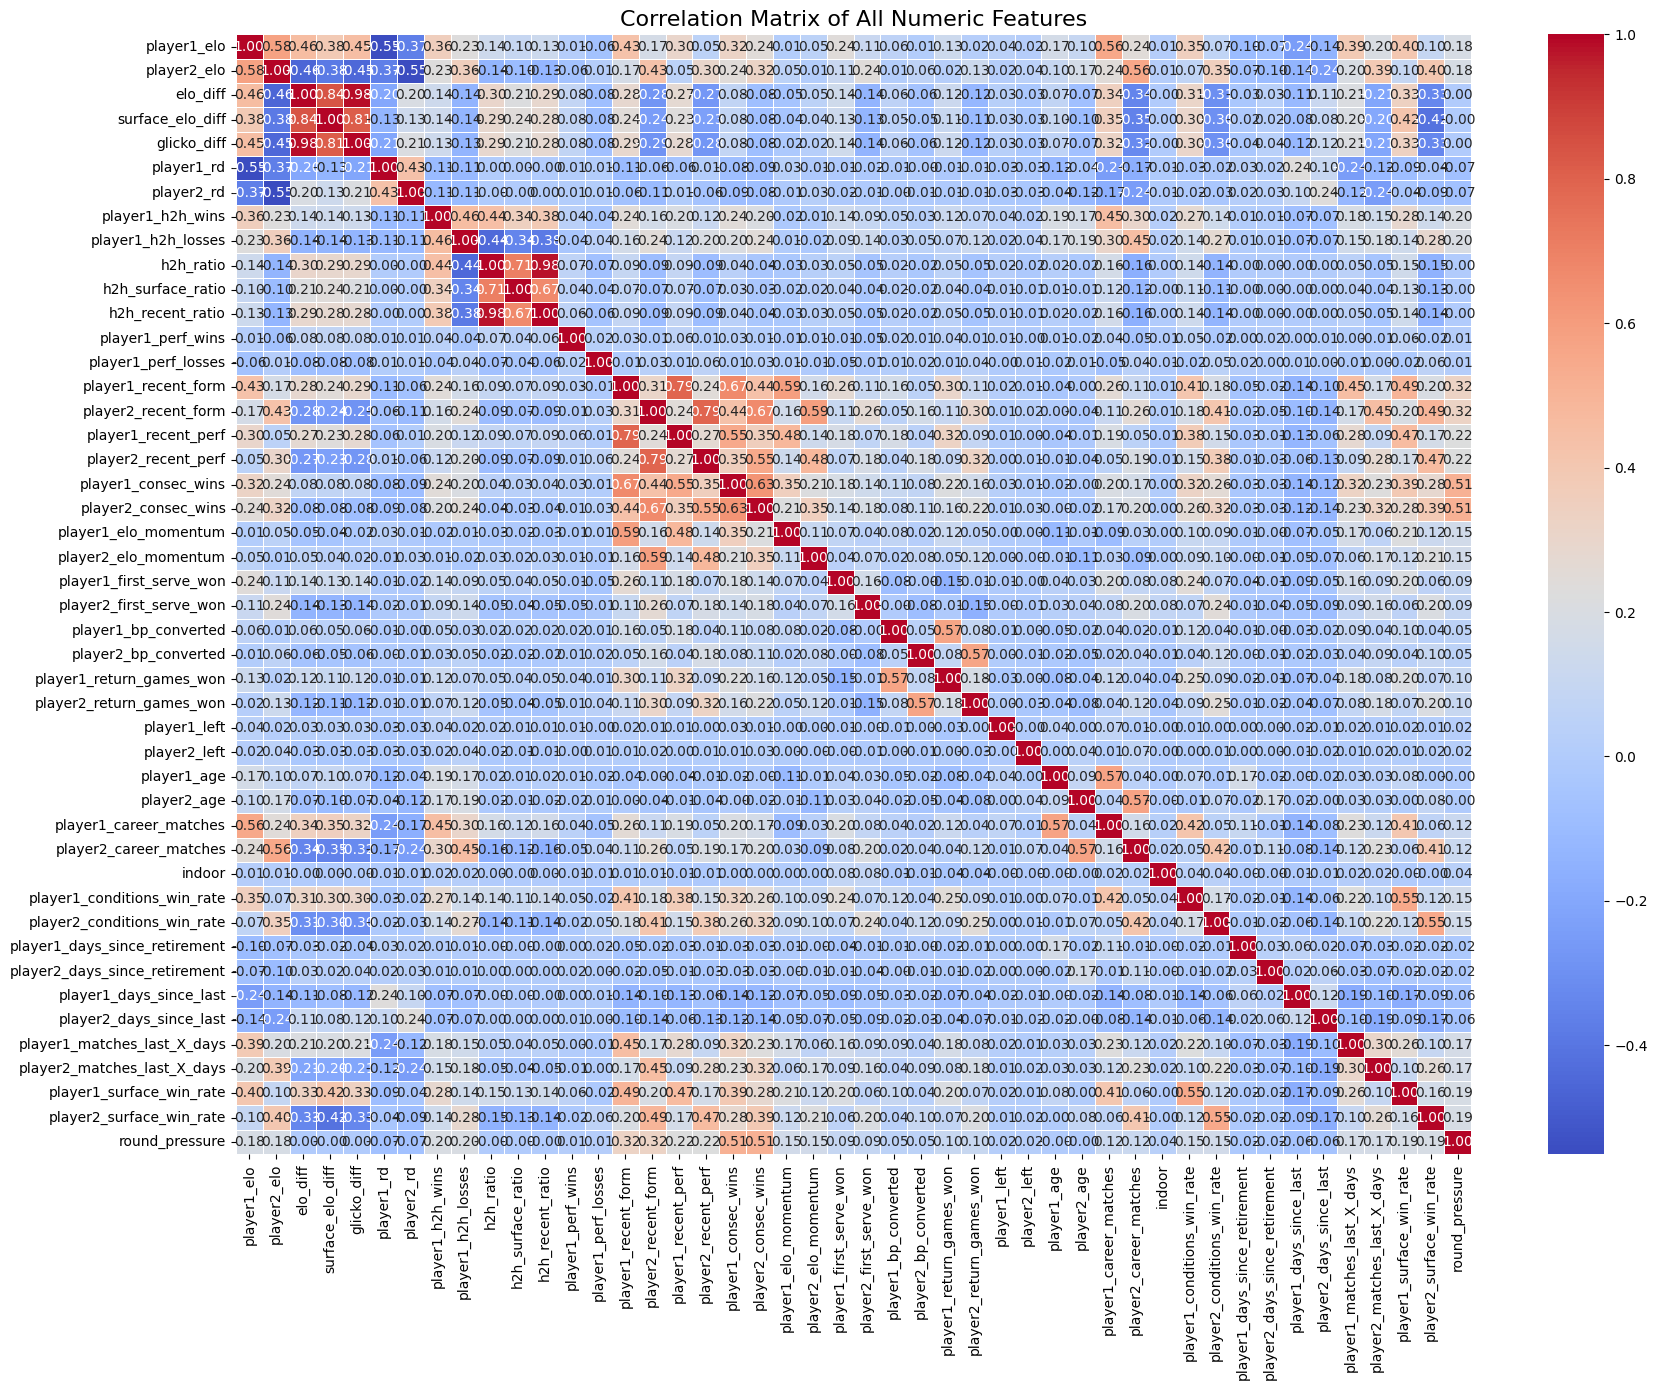

Ranking of columns by number of NaN values:
player1_perf_wins                283796
player1_perf_losses              283796
player1_bp_converted             184636
player2_bp_converted             184636
player1_first_serve_won          184341
player2_first_serve_won          184341
player2_return_games_won         184338
player1_return_games_won         184338
player2_days_since_retirement    159246
player1_days_since_retirement    159246
player1_conditions_win_rate      134109
player2_conditions_win_rate      134109
indoor                           127686
player1_surface_win_rate          15949
player2_surface_win_rate          15949
player2_left                       9751
player1_left                       9751
player2_recent_perf                7801
player1_recent_form                7801
player2_days_since_last            7801
player1_elo_momentum               7801
player2_consec_wins                7801
player1_days_since_last            7801
player2_elo_momentum               7

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif

# Convert to DataFrame
X_df = pd.DataFrame(match_data)

# Create the target variable
y = X_df.pop('outcome')

# Handle categorical variables with one-hot encoding
X = pd.get_dummies(X_df, columns=['surface', 'tourney_level', 'round'], drop_first=True)

# Drop non-predictive columns
X = X.drop(columns=['tourney_date'], errors='ignore')

# Only keep numeric columns for analysis
X_numeric = X.select_dtypes(include=[np.number])

# Replace any inf values with NaN, then fill NaNs with column means
X_numeric = X_numeric.replace([np.inf, -np.inf], np.nan)
col_means = X_numeric.mean()
X_numeric = X_numeric.fillna(col_means)

print(f"\nFeatures available for analysis: {X_numeric.shape[1]}")

# Split data for model training
X_train, X_test, y_train, y_test = train_test_split(X_numeric, y, test_size=0.2, random_state=42, stratify=y)

# FEATURE ANALYSIS METHODS

# 1. Correlation Analysis (Pearson)
correlations = X_numeric.apply(lambda x: abs(x.corr(y)) if len(x.unique()) > 1 else 0)
correlations = correlations.sort_values(ascending=False)

print("\nTop 10 features by correlation:")
print(correlations.head(10))

# 2. Mutual Information
mi_scores = mutual_info_classif(X_numeric, y)
mi_df = pd.DataFrame({'Feature': X_numeric.columns, 'MI_Score': mi_scores})
mi_df = mi_df.sort_values(by='MI_Score', ascending=False)

print("\nTop 10 features by Mutual Information:")
print(mi_df.head(10))

# VISUALIZATIONS

# Correlation heatmap of all features (with numbers)
plt.figure(figsize=(18, 14))
correlation_matrix = X_numeric.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of All Numeric Features', fontsize=16)
plt.tight_layout()
plt.show()

nan_counts = X_df.isna().sum().sort_values(ascending=False)
nan_ranking = nan_counts[nan_counts > 0]

print("Ranking of columns by number of NaN values:")
print(nan_ranking)

In [30]:
from sklearn.feature_selection import RFECV, f_classif
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
import pandas as pd

# Additional tests for feature selection and evaluation

# 1. Recursive Feature Elimination (RFE) with cross-validation

# Use a simple model (e.g., logistic regression or random forest)
estimator = LogisticRegression(max_iter=1000, solver='liblinear')
rfecv = RFECV(estimator, step=1, cv=5, scoring='accuracy', n_jobs=-1)
rfecv.fit(X_train, y_train)

print("Optimal number of features (RFE):", rfecv.n_features_)
print("Top features selected by RFE:")
print(list(X_train.columns[rfecv.support_]))

# 2. Feature importance from Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
importances = pd.Series(rf.feature_importances_, index=X_train.columns)
print("\nTop 10 features by Random Forest importance:")
print(importances.sort_values(ascending=False).head(10))

# 3. Permutation Importance (model-agnostic)
# n_jobs=1: every worker gets its own copy of the (large) forest, with -1 that ran out of RAM and killed VS Code
perm = permutation_importance(rf, X_test, y_test, n_repeats=5, random_state=42, n_jobs=1)
perm_importances = pd.Series(perm.importances_mean, index=X_test.columns)
print("\nTop 10 features by permutation importance:")
print(perm_importances.sort_values(ascending=False).head(10))

# 4. SHAP values (for model interpretability, optional, requires shap package)
# import shap
# explainer = shap.TreeExplainer(rf)
# shap_values = explainer.shap_values(X_test)
# shap.summary_plot(shap_values[1], X_test)

# 5. Univariate statistical tests (e.g., ANOVA F-test)
f_scores, p_values = f_classif(X_train, y_train)
f_df = pd.DataFrame({'Feature': X_train.columns, 'F_score': f_scores, 'p_value': p_values})
print("\nTop 10 features by ANOVA F-test:")
print(f_df.sort_values('F_score', ascending=False).head(10))

# These tests, combined with correlation and mutual information, give a robust picture of feature importance.

Optimal number of features (RFE): 39
Top features selected by RFE:
['player1_elo', 'player2_elo', 'elo_diff', 'surface_elo_diff', 'glicko_diff', 'player1_rd', 'player2_rd', 'player1_h2h_wins', 'player1_h2h_losses', 'h2h_ratio', 'h2h_surface_ratio', 'h2h_recent_ratio', 'player1_perf_wins', 'player1_perf_losses', 'player1_recent_form', 'player2_recent_form', 'player1_recent_perf', 'player2_recent_perf', 'player1_consec_wins', 'player2_consec_wins', 'player1_elo_momentum', 'player2_elo_momentum', 'player1_first_serve_won', 'player2_first_serve_won', 'player1_bp_converted', 'player2_bp_converted', 'player1_return_games_won', 'player2_return_games_won', 'player1_left', 'player2_left', 'player1_age', 'player2_age', 'indoor', 'player1_conditions_win_rate', 'player2_conditions_win_rate', 'player1_matches_last_X_days', 'player2_matches_last_X_days', 'player1_surface_win_rate', 'player2_surface_win_rate']



Top 10 features by Random Forest importance:
glicko_diff                 0.090290
elo_diff                    0.086492
surface_elo_diff            0.072233
player1_elo                 0.033628
player2_elo                 0.032575
player1_age                 0.031203
player1_rd                  0.031168
player2_age                 0.030998
player2_surface_win_rate    0.030957
player2_rd                  0.030856
dtype: float64



Top 10 features by permutation importance:
surface_elo_diff            0.019339
elo_diff                    0.015599
glicko_diff                 0.007514
player2_rd                  0.002165
player1_rd                  0.002120
player2_age                 0.002098
player1_elo                 0.001781
player1_surface_win_rate    0.001617
player1_age                 0.001512
player2_elo_momentum        0.001186
dtype: float64

Top 10 features by ANOVA F-test:
                        Feature       F_score  p_value
2                      elo_diff  76480.870943      0.0
4                   glicko_diff  74128.045051      0.0
3              surface_elo_diff  68290.306302      0.0
0                   player1_elo  13511.671267      0.0
1                   player2_elo  13410.374238      0.0
43     player1_surface_win_rate   9377.544882      0.0
44     player2_surface_win_rate   9248.972706      0.0
9                     h2h_ratio   8458.266724      0.0
11             h2h_recent_ratio   7626.710

Here’s an updated analysis of feature importance based on the latest correlation and mutual information (MI) results:

---

### Key Feature Groups (2025 Update)

1. **ELO-Based Features:**
   - `elo_diff` and `surface_elo_diff` are the most strongly correlated with match outcome and also have the highest MI scores. These features capture the overall and surface-specific strength difference between players.
   - `player1_elo` and `player2_elo` also show moderate correlation and MI, but are less informative than the difference features.
   - **Recommendation:** Retain `elo_diff` and `surface_elo_diff` as the main ELO-based predictors. Raw ELO values (`player1_elo`, `player2_elo`) can be dropped to reduce redundancy.

2. **Head-to-Head (H2H) Features:**
   - `h2h_ratio` is consistently among the top features by both correlation and MI, confirming its value as the best single indicator of direct matchup history.
   - **Recommendation:** Keep only `h2h_ratio` to represent H2H history.

3. **Recent Performance/Form:**
   - `player1_recent_perf`, `player2_recent_perf`, `player1_recent_form`, and `player2_recent_form` all show moderate correlation and MI, indicating that recent results and form are useful but less decisive than ELO or H2H.
   - **Recommendation:** Optionally retain recent performance metrics, especially if you want to capture short-term trends.

4. **Other Features:**
   - Features like `player1_perf_losses` and `player1_h2h_losses` appear in the MI and correlation top 10, but their predictive value is likely captured by the main difference and ratio features above.

---

### Summary

- **ELO Features:** Keep `elo_diff` and `surface_elo_diff` (drop raw ELOs).
- **Head-to-Head:** Keep only `h2h_ratio`.
- **Recent Form:** Optionally include recent performance/form metrics for added nuance.

**This selection focuses on the most predictive and least redundant features, maximizing model performance based on the latest correlation and MI analysis.**